# Assignment 2: Level-Up Hobby & Interest Classification (Books / Cosmetics / Flowers)
Ismail Akniet Zhibek Tolegen
ST2405


**SOTA component:** DINOv2 (self-supervised Vision Transformer, Meta AI) used as a frozen feature extractor + lightweight classifier.

**Explainability:** (1) ViT attention heatmap, (2) nearest-neighbors gallery.


In [1]:
!pip -q install gradio transformers scikit-learn

## 1. Data (same split as A1)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split

dataset_path = "/content/drive/MyDrive/My_Computer_Vision_Project/dataset"
classes = ["books", "cosmetics", "flowers"]
EXT = (".jpg", ".jpeg", ".png", ".webp")

train_files, val_files, test_files = [], [], []
for c in classes:
    folder = os.path.join(dataset_path, c)
    files = [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(EXT)]
    train, temp = train_test_split(files, test_size=0.30, random_state=42)
    val, test = train_test_split(temp, test_size=0.50, random_state=42)
    train_files += train; val_files += val; test_files += test

def labels(files):
    return np.array([classes.index(os.path.basename(os.path.dirname(f))) for f in files])

y_train, y_val, y_test = labels(train_files), labels(val_files), labels(test_files)
print("Train/Val/Test:", len(train_files), len(val_files), len(test_files))

Mounted at /content/drive
Train/Val/Test: 225 48 51


## 2. SOTA model: DINOv2 feature extractor

In [3]:
from transformers import AutoImageProcessor, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "facebook/dinov2-base"
proc = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation="eager").to(device).eval()
print("Device:", device)

def load(paths):
    return [Image.open(p).convert("RGB") for p in paths]

@torch.no_grad()
def embed(images, bs=32):
    out = []
    for i in range(0, len(images), bs):
        inp = proc(images=images[i:i+bs], return_tensors="pt").to(device)
        out.append(model(**inp).pooler_output.cpu().numpy())
    e = np.concatenate(out)
    return e / np.linalg.norm(e, axis=1, keepdims=True)

imgs_train, imgs_val, imgs_test = load(train_files), load(val_files), load(test_files)
X_train, X_val, X_test = embed(imgs_train), embed(imgs_val), embed(imgs_test)
X_train_flip = embed([ImageOps.mirror(im) for im in imgs_train])   # augmentation for ablation
print(X_train.shape, X_val.shape, X_test.shape)

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Device: cuda
(225, 768) (48, 768) (51, 768)


## 3. Classifier + comparison with A1 baseline

              precision    recall  f1-score   support

       books       1.00      1.00      1.00        18
   cosmetics       1.00      1.00      1.00        17
     flowers       1.00      1.00      1.00        16

    accuracy                           1.00        51
   macro avg       1.00      1.00      1.00        51
weighted avg       1.00      1.00      1.00        51



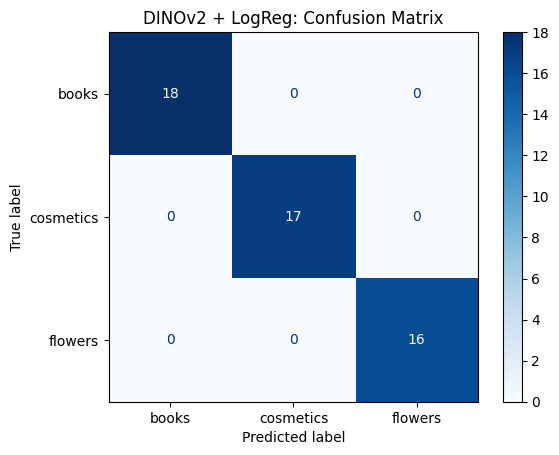

             Model  Accuracy  F1 (weighted)
   A1 Baseline CNN    0.8235            NaN
   A1 Improved CNN    0.9412         0.9412
A2 DINOv2 + LogReg    1.0000         1.0000


In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

clf = LogisticRegression(max_iter=2000).fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, target_names=classes, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(cmap="Blues")
plt.title("DINOv2 + LogReg: Confusion Matrix"); plt.show()

# A1 numbers taken from the A1 notebook (test set, 51 images)
rows = [
    ["A1 Baseline CNN", 0.8235, None],
    ["A1 Improved CNN", 0.9412, 0.9412],
    ["A2 DINOv2 + LogReg", accuracy_score(y_test, pred), f1_score(y_test, pred, average="weighted")],
]
print(pd.DataFrame(rows, columns=["Model", "Accuracy", "F1 (weighted)"]).round(4).to_string(index=False))

## 4. Ablation: with / without flip augmentation

In [5]:
clf_aug = LogisticRegression(max_iter=2000).fit(
    np.concatenate([X_train, X_train_flip]), np.concatenate([y_train, y_train]))
pred_aug = clf_aug.predict(X_test)

abl = pd.DataFrame([
    ["No augmentation", accuracy_score(y_test, pred), f1_score(y_test, pred, average="weighted")],
    ["+ horizontal flip", accuracy_score(y_test, pred_aug), f1_score(y_test, pred_aug, average="weighted")],
], columns=["Setting", "Accuracy", "F1 (weighted)"])
print(abl.round(4).to_string(index=False))

          Setting  Accuracy  F1 (weighted)
  No augmentation       1.0            1.0
+ horizontal flip       1.0            1.0


## 5. Explainability: attention heatmap + nearest neighbors

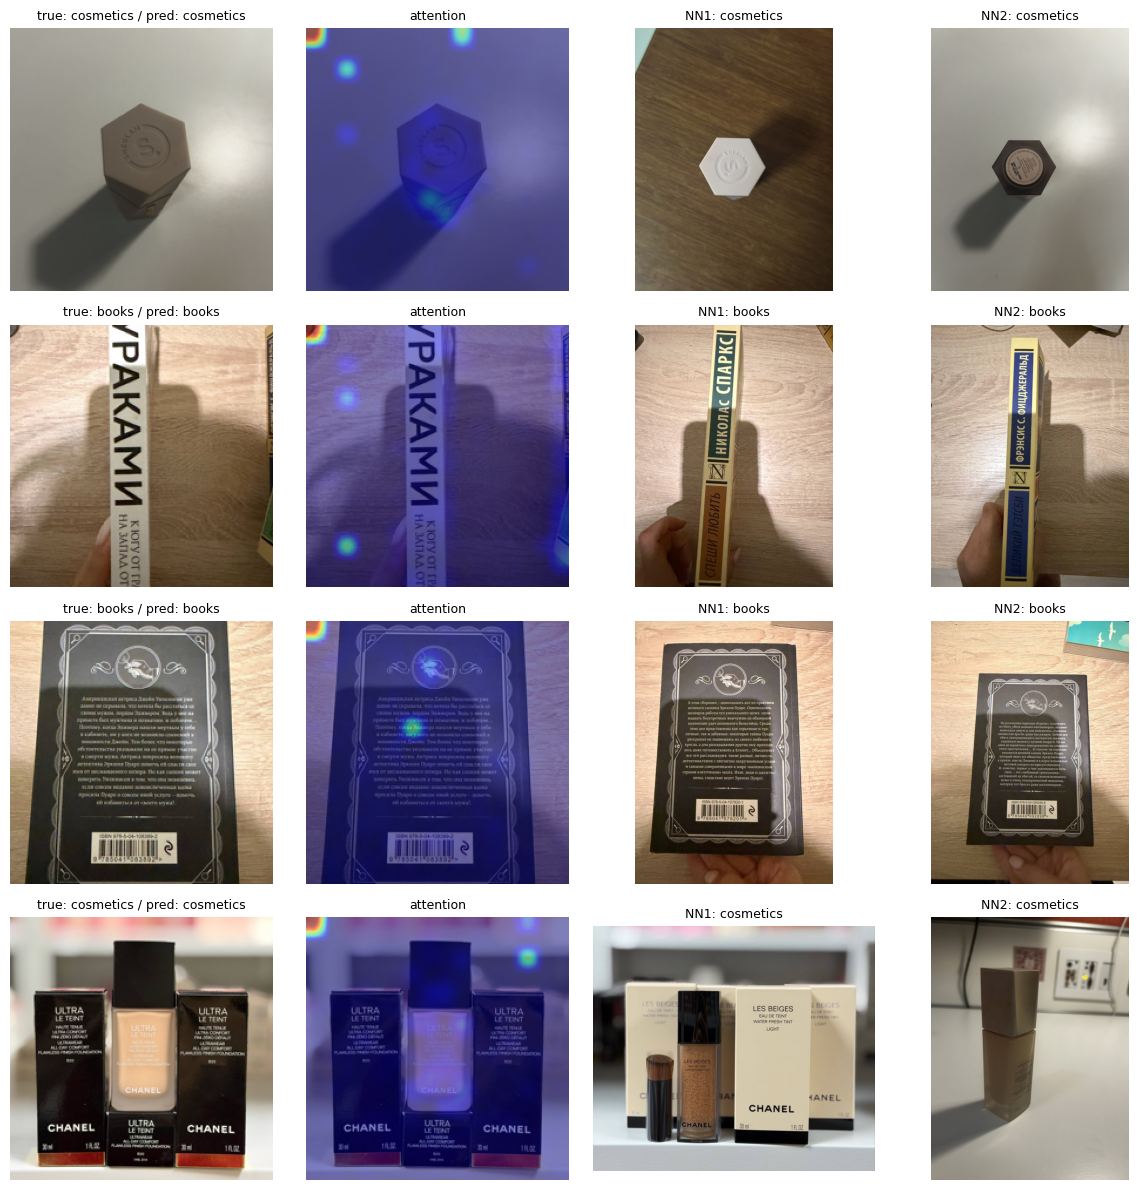

In [6]:
import matplotlib.cm as cm

def center_view(img):
    w, h = img.size; s = 256 / min(w, h)
    img = img.resize((round(w*s), round(h*s)))
    w, h = img.size; l, t = (w-224)//2, (h-224)//2
    return img.crop((l, t, l+224, t+224))

@torch.no_grad()
def attention_overlay(img):
    inp = proc(images=img, return_tensors="pt").to(device)
    att = model(**inp, output_attentions=True).attentions[-1][0, :, 0, 1:].mean(0)
    n = int(att.numel() ** 0.5)
    att = att.reshape(n, n).cpu().numpy()
    att = (att - att.min()) / (att.max() - att.min() + 1e-8)
    heat = np.array(Image.fromarray((att*255).astype("uint8")).resize((224, 224), Image.BICUBIC)) / 255.0
    colored = (cm.jet(heat)[:, :, :3] * 255).astype("uint8")
    base = np.array(center_view(img))
    return Image.fromarray((0.5*base + 0.5*colored).astype("uint8"))

def neighbors(emb, k=4):
    idx = np.argsort(-(X_train @ emb))[:k]
    return [(imgs_train[i], classes[y_train[i]]) for i in idx]

# visualize 4 test images: original | heatmap | 2 nearest neighbors
plt.figure(figsize=(12, 12))
for r, i in enumerate(np.random.RandomState(0).choice(len(imgs_test), 4, replace=False)):
    img = imgs_test[i]
    nn = neighbors(X_test[i], 2)
    panels = [(center_view(img), f"true: {classes[y_test[i]]} / pred: {classes[pred[i]]}"),
              (attention_overlay(img), "attention"),
              (nn[0][0], "NN1: " + nn[0][1]), (nn[1][0], "NN2: " + nn[1][1])]
    for c, (im, title) in enumerate(panels):
        plt.subplot(4, 4, r*4 + c + 1); plt.imshow(im); plt.title(title, fontsize=9); plt.axis("off")
plt.tight_layout(); plt.show()

## 6. Latency

In [7]:
times = []
for im in imgs_test[:20]:
    t0 = time.time()
    e = embed([im]); clf.predict_proba(e)
    times.append((time.time() - t0) * 1000)
print(f"Average inference time: {np.mean(times):.1f} ms/image on {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))

Average inference time: 42.4 ms/image on cuda (Tesla T4)


## 7. Interactive app (Gradio)

In [8]:
import gradio as gr

def predict(img):
    t0 = time.time()
    img = img.convert("RGB")
    e = embed([img])
    probs = clf.predict_proba(e)[0]
    over = attention_overlay(img)
    gallery = neighbors(e[0], 4)
    ms = (time.time() - t0) * 1000
    return ({c: float(p) for c, p in zip(classes, probs)}, over, gallery,
            f"{ms:.0f} ms | device: {device} | model: {MODEL_NAME}")

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload or take a photo"),
    outputs=[gr.Label(label="Prediction"),
             gr.Image(label="Attention heatmap (what the model looks at)"),
             gr.Gallery(label="Nearest training images"),
             gr.Textbox(label="Latency / environment")],
    title="Hobby & Interest Classifier: Books / Cosmetics / Flowers",
    description="DINOv2 + Logistic Regression. Real photos only; no synthetic media used.",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f774b04b4d00dd7801.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Notes for the report
- **Dataset:** 324 real images, 0% synthetic. Test set is only 51 images, so one error is ~2%.
- **SOTA:** DINOv2 (self-supervised ViT). Why it helps: pretrained on huge data, so features are robust with small datasets.
- **Limitations:** small test set; near-duplicate web images may leak across splits; faces (if any in cosmetics ads) = privacy.
- **Reproducibility:** Colab T4, `transformers`, `gradio`, `scikit-learn`; split `random_state=42`.